# Horizontal Light Extinction over the Sea

How much light from an LED lamp survives a 1–2 km horizontal path through a marine aerosol layer?

libRadtran is a **1D plane-parallel** model: its sources are the sun or thermal emission, and all paths are slanted through horizontally homogeneous layers. There is no point source and no purely horizontal path. What libRadtran *does* know precisely is the aerosol and molecular **extinction coefficient** of every layer at every wavelength — and for a homogeneous layer, that is all a horizontal Beer–Lambert calculation needs.

The trick:

1. Put the sun at the zenith (`sza = 0`), so the direct beam travels straight down.
2. Output the direct irradiance $E_\mathrm{dir}$ at two levels $z_1 < z_2$ bracketing the lamp height.
3. The layer's volume extinction coefficient is

$$
\beta_\mathrm{ext}(\lambda) = \frac{\ln E_\mathrm{dir}(z_2, \lambda) - \ln E_\mathrm{dir}(z_1, \lambda)}{z_2 - z_1}
$$

4. The horizontal transmission over a distance $L$ at that height is

$$
T(\lambda, L) = \exp\left(-\beta_\mathrm{ext}(\lambda)\,L\right)
$$

$\beta_\mathrm{ext}$ contains aerosol extinction, Rayleigh scattering and gas absorption, all from the same optical properties libRadtran would use in a full radiative-transfer run.

In [1]:
import pyradtran  # Registers the .pyradtran xarray accessor
from pyradtran import Var
from pyradtran import load_config
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr
from pathlib import Path
import pandas as pd
import logging

# Suppress pyradtran log output for cleaner notebook cells
logging.getLogger('pyradtran').setLevel(logging.CRITICAL)

## Configuration

Only the direct beam matters here, so the solver choice barely affects the result — we use `disort` for consistency with the other notebooks. `reptran fine` resolves gas absorption at 1 nm, and `sza = 0` overrides the solar position calculated from time and location.

In [2]:
cfg = load_config()
cfg.simulation_defaults.rte_solver           = "disort"
cfg.simulation_defaults.mol_abs_param        = "reptran fine"
cfg.simulation_defaults.source               = "solar"
cfg.simulation_defaults.wavelength_nm        = [400, 750]
cfg.simulation_defaults.integrate_wavelength = False
cfg.simulation_defaults.sza                  = 0.0
cfg.simulation_defaults.output_columns       = ["zout", "lambda", "edir"]
cfg.execution.max_workers                    = 8
config_path = Path("config/led_extinction.yaml")
cfg.to_yaml(config_path)

print(f"Config: {config_path}")

Config: config/led_extinction.yaml


## Setup: Visibility Scenarios

Each time step of the input dataset is one aerosol scenario. We sweep the horizontal **visibility** from hazy (5 km) to very clear (50 km) and pass it to libRadtran per point with `Var`.

The two altitude levels (0 and 100 m) bracket a lamp mounted a few metres above the sea surface. The location is a North Sea coordinate; with `sza` fixed it only matters for the day of year.

In [3]:
visibility_km = [5, 10, 20, 50]
N_scenarios = len(visibility_km)

ds = xr.Dataset(
    coords={
        'time'      : pd.date_range('2025-06-21T12:00:00', periods=N_scenarios, freq='s'),
        'latitude'  : ('time', [54.2] * N_scenarios),
        'longitude' : ('time', [7.9] * N_scenarios),
        'altitude'  : ('altitude', [0.0, 0.1]),  # km, brackets the lamp height
    },
    data_vars={
        'visibility': ('time', visibility_km),  # km
    }
)

ds

<xarray.Dataset> Size: 144B
Dimensions:     (time: 4, altitude: 2)
Coordinates:
  * time        (time) datetime64[ns] 32B 2025-06-21T12:00:00 ... 2025-06-21T...
    latitude    (time) float64 32B 54.2 54.2 54.2 54.2
    longitude   (time) float64 32B 7.9 7.9 7.9 7.9
  * altitude    (altitude) float64 16B 0.0 0.1
Data variables:
    visibility  (time) int64 32B 5 10 20 50

## Run: Maritime Aerosol vs. Clean Air

`aerosol_default` switches on the Shettle (1989) aerosol model, `aerosol_haze 4` selects the **maritime** boundary-layer type, and `aerosol_visibility` scales its extinction to the requested visibility.

A second run without aerosol gives the molecular (Rayleigh + gas) background.

In [4]:
ds_aer = ds.pyradtran.run(
    config_path=config_path,
    return_dataset=True,
    save_to_file=False,
    params={
        'aerosol_default'   : None,
        'aerosol_haze'      : 4,  # maritime
        'aerosol_visibility': Var('visibility'),
    },
    show_progress=False,
)

ds_clean = ds.isel(time=[0]).pyradtran.run(
    config_path=config_path,
    return_dataset=True,
    save_to_file=False,
    show_progress=False,
)

ds_aer

<xarray.Dataset> Size: 25kB
Dimensions:     (time: 4, wavelength: 351, altitude: 2)
Coordinates:
  * time        (time) datetime64[ns] 32B 2025-06-21T12:00:00 ... 2025-06-21T...
  * wavelength  (wavelength) float64 3kB 400.0 401.0 402.0 ... 748.0 749.0 750.0
  * altitude    (altitude) float64 16B 0.0 0.1
Data variables:
    edir        (time, wavelength, altitude) float64 22kB 241.1 ... 1.057e+03
    status      (time) int64 32B 0 0 0 0
Attributes:
    generated_by:              pyradtran
    generation_date:           2026-09-28T14:23:29.728077
    pyradtran_version:         0.2.0
    history:                   2026-09-28T14:23:29: pyradtran 0.2.0 ds.pyradt...
    pyradtran_params:          {"aerosol_default": null, "aerosol_haze": 4, "...
    pyradtran_libradtran_bin:  /opt/libRadtran-2.0.6/bin/uvspec
    pyradtran_config:          paths: {libradtran_bin: /opt/libRadtran-2.0.6/...
    pyradtran_input_example:   rte_solver disort                             ...

## Extinction Coefficient

Applying the log-difference formula to the direct irradiance gives $\beta_\mathrm{ext}$ in km⁻¹.

Text(0.5, 1.0, '')

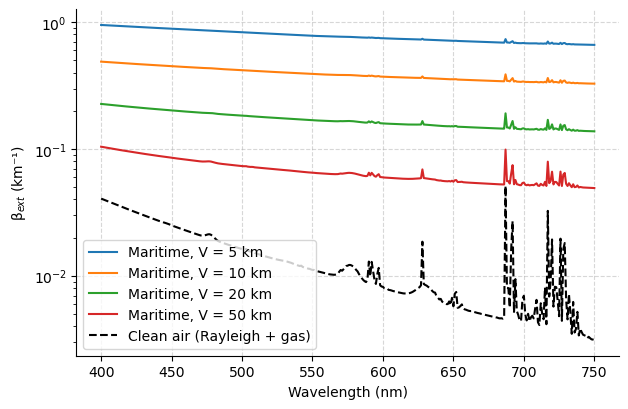

In [5]:
def extinction_coefficient(ds_sim):
    """Volume extinction coefficient (km⁻¹) of the layer between the two zout levels."""
    z1, z2 = ds_sim.altitude.values
    beta = (np.log(ds_sim.edir.sel(altitude=z2)) - np.log(ds_sim.edir.sel(altitude=z1))) / (z2 - z1)
    return beta.rename('beta_ext').assign_attrs(units='km-1', long_name='Extinction coefficient')

beta_aer   = extinction_coefficient(ds_aer).assign_coords(visibility=('time', visibility_km)).swap_dims(time='visibility')
beta_clean = extinction_coefficient(ds_clean).isel(time=0)

fig, ax = plt.subplots(figsize=(7, 4.5))

for vis in visibility_km:
    beta_aer.sel(visibility=vis).plot(ax=ax, lw=1.5, label=f'Maritime, V = {vis} km')
beta_clean.plot(ax=ax, color='black', ls='--', lw=1.5, label='Clean air (Rayleigh + gas)')

ax.set_yscale('log')
ax.set_xlabel('Wavelength (nm)')
ax.set_ylabel('β$_{ext}$ (km⁻¹)')
ax.legend()
ax.spines[['top', 'right']].set_visible(False)
ax.grid(True, linestyle='--', alpha=0.5)
ax.set_title('')

### Sanity Check: Koschmieder

Meteorological visibility is defined through the Koschmieder relation $V = 3.912 / \beta_\mathrm{ext}(550\,\mathrm{nm})$. Recovering the input visibility from the simulated extinction checks the method.

In [6]:
beta_550 = beta_aer.sel(wavelength=550)

pd.DataFrame({
    'input visibility (km)'     : visibility_km,
    'β_ext at 550 nm (km⁻¹)'   : beta_550.values.round(4),
    'Koschmieder 3.912/β (km)'  : (3.912 / beta_550.values).round(2),
})

,input visibility (km),β_ext at 550 nm (km⁻¹),Koschmieder 3.912/β (km)
0,5,0.7811,5.01
1,10,0.3901,10.03
2,20,0.1686,23.20
3,50,0.0650,60.19


The match is exact at 5 and 10 km. For clearer air, libRadtran's Shettle profile puts less extinction into the lowest layer than the Koschmieder relation implies (50 km input → ~60 km recovered). Treat `aerosol_visibility` as a scenario knob and use the simulated $\beta_\mathrm{ext}$ — not the nominal visibility — for the transmission.

## LED Transmission over 0–2 km

LEDs are not monochromatic. We model each lamp as a Gaussian emission line (peak wavelength, FWHM) and weight the spectral transmission with it:

$$
T_\mathrm{LED}(L) = \frac{\int S(\lambda)\, e^{-\beta_\mathrm{ext}(\lambda) L}\, d\lambda}{\int S(\lambda)\, d\lambda}
$$

Swap in measured LED spectra for real lamps.

(0.0, 1.0)

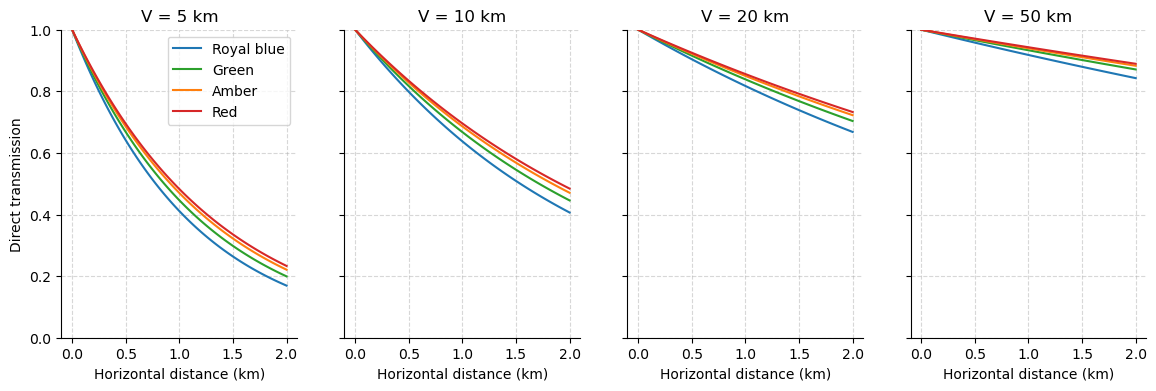

In [7]:
# ── LED emission spectra: peak (nm), FWHM (nm) ───────────────────────────────
leds = {
    'Royal blue': (450, 20, 'tab:blue'),
    'Green'     : (525, 30, 'tab:green'),
    'Amber'     : (590, 15, 'tab:orange'),
    'Red'       : (630, 18, 'tab:red'),
}

wavelength = beta_aer.wavelength
distance_km = xr.DataArray(np.linspace(0, 2, 101), dims='distance', attrs={'units': 'km'})

def led_spectrum(peak_nm, fwhm_nm):
    sigma = fwhm_nm / (2 * np.sqrt(2 * np.log(2)))
    return np.exp(-0.5 * ((wavelength - peak_nm) / sigma) ** 2)

def led_transmission(beta, peak_nm, fwhm_nm):
    s = led_spectrum(peak_nm, fwhm_nm)
    return (s * np.exp(-beta * distance_km)).sum('wavelength') / s.sum('wavelength')

transmission = xr.concat(
    [led_transmission(beta_aer, peak, fwhm) for peak, fwhm, _ in leds.values()],
    dim=pd.Index(list(leds), name='led'),
).assign_coords(distance=distance_km)

fig, axes = plt.subplots(1, N_scenarios, figsize=(14, 4), sharey=True)

for ax, vis in zip(axes, visibility_km):
    for name, (_, _, color) in leds.items():
        transmission.sel(led=name, visibility=vis).plot(ax=ax, color=color, lw=1.5, label=name)
    ax.set_title(f'V = {vis} km')
    ax.set_xlabel('Horizontal distance (km)')
    ax.set_ylabel('')
    ax.spines[['top', 'right']].set_visible(False)
    ax.grid(True, linestyle='--', alpha=0.5)

axes[0].set_ylabel('Direct transmission')
axes[0].legend()
axes[0].set_ylim(0, 1)

In [8]:
# Direct transmission at 1 and 2 km
(
    transmission.sel(distance=[1.0, 2.0])
    .to_series()
    .unstack(['visibility', 'distance'])
    .round(3)
)

visibility     5             10            20            50       
distance      1.0    2.0    1.0    2.0    1.0    2.0    1.0    2.0
led                                                               
Royal blue  0.411  0.169  0.638  0.406  0.817  0.668  0.918  0.843
Green       0.446  0.199  0.668  0.446  0.839  0.704  0.933  0.871
Amber       0.470  0.221  0.686  0.471  0.850  0.723  0.940  0.883
Red         0.483  0.233  0.696  0.484  0.856  0.733  0.943  0.889

### Interpretation

- **Aerosol dominates.** Even at 50 km visibility, maritime aerosol extinction exceeds the Rayleigh background at red wavelengths; at 5–10 km it is larger by more than an order of magnitude.
- **Red goes farthest.** Extinction decreases with wavelength, so red and amber LEDs keep more of their direct beam than blue ones. Because the spectral difference in $\beta_\mathrm{ext}$ is multiplied by the path length, the colour gap widens in haze and over longer distances.
- **Distance is exponential.** Doubling the path from 1 to 2 km squares the transmission — at 5 km visibility a 2 km path passes only about a fifth of the direct beam.

## Limitations and Knobs

- **Direct beam only.** $T$ is the Beer–Lambert (unscattered) transmission. Maritime aerosol scatters strongly forward, so a detector with a wide field of view also collects forward-scattered light and sees *more* than $T$. For a narrow-FOV receiver or path optical depths $\beta L \lesssim 1$, the direct beam is the relevant quantity.
- **Homogeneous path.** The lamp and receiver sit in the same model layer. For different heights, add more `altitude` levels and integrate $\beta_\mathrm{ext}(z)$ along the slant path.
- **Aerosol model.** `aerosol_haze` also offers rural (1), urban (5) and tropospheric (6) types. For OPAC mixtures (e.g. `maritime_clean`, `maritime_polluted`) use `aerosol_species_file`; humidity growth of sea salt then follows the atmosphere's relative humidity.
- **Measured aerosol.** With measured AOD or extinction profiles, `aerosol_file tau`, `aerosol_angstrom` and `aerosol_modify` take over from the visibility scaling.